In [ ]:
import os 
import sys 

from pathlib import Path

from sklearn.model_selection import train_test_split
import tensorflow as tf
import tensorflow_hub as hub
import cv2 
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

import random

I0000 00:00:1792668149.091170   12115 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792668149.105183   12115 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792668149.867920   12115 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792668151.942114   12115 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

In [ ]:
ROOT_DIR = Path('/home/fangyuan/Projects/Diagnostic-des-tumeurs')

VALID_EXTENSIONS = ('.jpeg' , '.jpg' , '.png' , '.bmp' )
IMG_SIZE = (224, 224)
DATA = ROOT_DIR / 'data' / 'Data'
SEED = 42 
BATCH_SIZE = 32
EPOCHS = 20
LEARNING_RATE = 0.001
MODEL_URL = 'https://www.kaggle.com/models/google/inception-v1/tensorFlow2/feature-vector/1?tfhub-redirect=true'

In [15]:
classes = sorted( dir.name for dir in DATA.iterdir() if dir.is_dir() )
class_to_id = { name : id for id, name in enumerate(classes) }
id_to_class = { id : name for name, id in class_to_id.items()}

In [ ]:
def load_data(path: Path, classes: list[str] , class_to_id: dict) -> tuple[list[Path], list[int]] : 
    """
    Load the data from the given path and return the paths and labels.
    """
    paths, labels = [], [] 
    for class_name in classes : 
        class_dir = path / class_name   
        for file in class_dir.iterdir() : 
            if file.suffix.lower() in VALID_EXTENSIONS : 
                paths.append(file) 
                labels.append(class_to_id[class_name])
    return paths, labels


In [ ]:
def load_image(path, label) : 
    try : 
        image = cv2.imread(str(path))

        if image is None : 
            raise FileNotFoundError(f"Image not found or cannot be read: {path}")

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, IMG_SIZE) 

        return image, label 

    except cv2.error as e : 
        print(f"Error reading image {path}: {e}")
        return None, None

    except FileNotFoundError as e : 
        print(e)
        return None, None



def make_data(paths , labels , training=False ) : 
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training : 
        ds = ds.shuffle(10000)

    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)

    ds = ds.batch(BATCH_SIZE)

    ds = ds.prefetch(tf.data.AUTOTUNE)

    return ds 




In [27]:
def apply_blur(image, label):
    blurred_image = cv2.GaussianBlur(image, (5, 5), 0)
    return blurred_image, label

def apply_flip(image): 
    flipped_image = cv2.flip(image, 1) # Horizontal flip
    return flipped_image

def apply_noise(image, label):
    # Convert the image to float32 for noise addition
    img_float = image.astype(np.float32)

    # Generate Gaussian noise with mean 0 and standard deviation 10
    noise = np.random.normal(loc=0, scale=10, size=image.shape)
    
    # Add the noise to the image and clip the values to be in the valid range [0, 255] 
    noisy_img = np.clip(img_float + noise, 0, 255).astype(np.uint8)


    # plt.subplot(1, 2, 1)
    # plt.imshow(image)
    # plt.title("Original image")
    # plt.axis("off")

    # plt.subplot(1, 2, 2)
    # plt.imshow(noisy_img)
    # plt.title("Gaussian noise")
    # plt.axis("off")

    # plt.show()

    return noisy_img, label

def augment_data(image, label) : 
    """ 
    Apply data augmentation techniques to the image and return the augmented image and label.
    """
    transformations = [apply_blur, apply_flip, apply_noise] 
    chosen_transformation = random.choice(transformations) 
    return chosen_transformation(image, label)

In [7]:
data_paths, data_labels = load_data(DATA, classes, class_to_id)

<Axes: ylabel='count'>

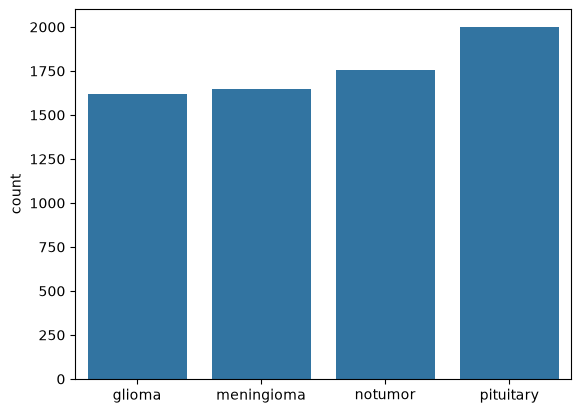

In [8]:
sns.barplot(x=classes, y=pd.Series(data_labels).value_counts().sort_index().sort_values(ascending=True))

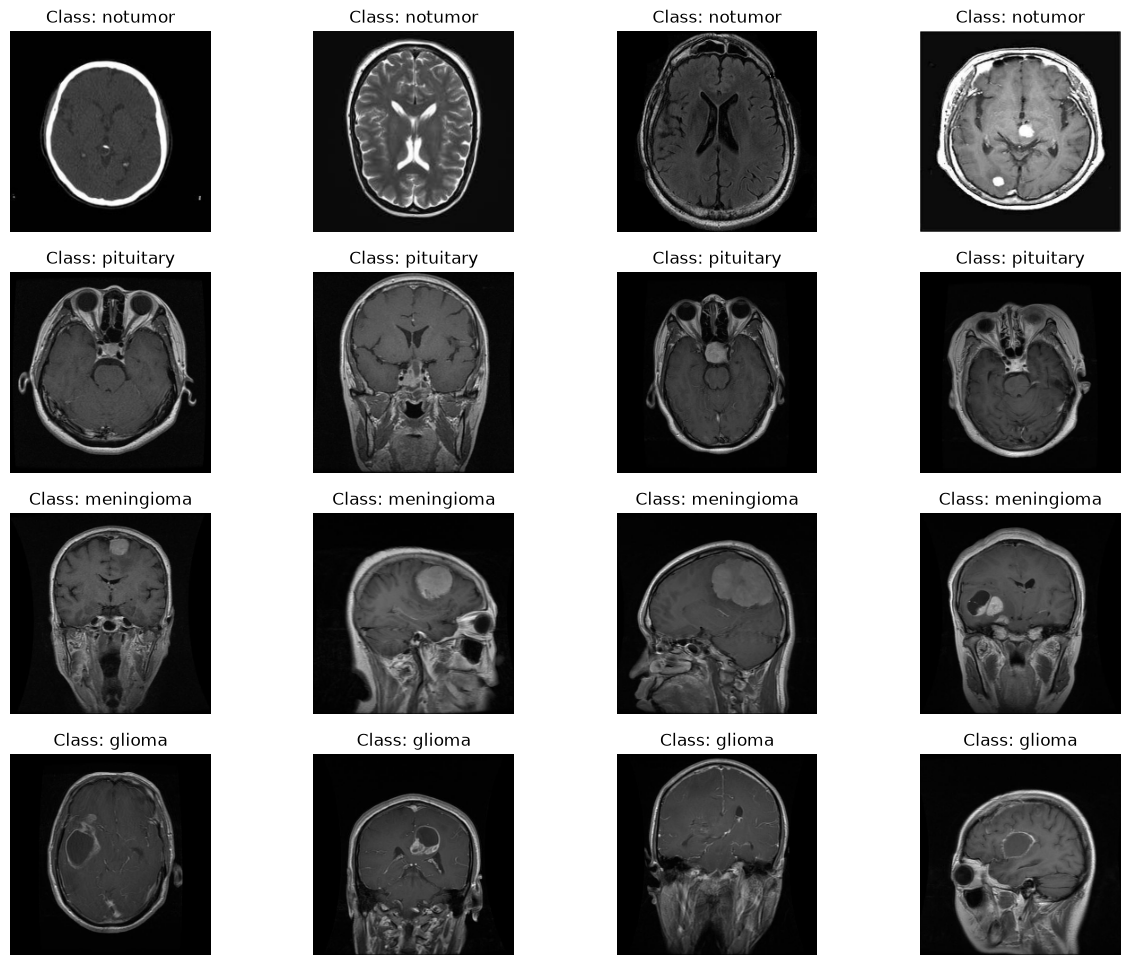

In [9]:
fig , axes = plt.subplots(4, 4, figsize=(15, 12))

for id , label in enumerate(pd.Series(data_labels).value_counts().index) :
    label_images = [data_paths[j] for j in range(len(data_labels)) if data_labels[j] == label]

    for i in range(4) : 
        image, _ = load_image(label_images[i], label)
        if image is not None : 
            axes[id, i].imshow(image)
            axes[id, i].set_title(f"Class: {classes[label]}")
            axes[id, i].axis('off')



In [10]:
X_train, X_temp, y_train, y_temp = train_test_split(
    data_paths,
    data_labels, 
    test_size=0.3, 
    random_state=SEED, 
    stratify=data_labels
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    random_state=SEED,
    stratify=y_temp
)

In [11]:
print(f"Training set: {len(X_train)} images")
print(f"Validation set: {len(X_val)} images")
print(f"Test set: {len(X_test)} images")

Training set: 4916 images
Validation set: 1053 images
Test set: 1054 images


In [12]:
print(classes)
print(pd.Series(y_train).value_counts().sort_index().sort_values(ascending=True))
print(class_to_id)


['glioma', 'meningioma', 'notumor', 'pituitary']
0    1135
1    1151
3    1230
2    1400
Name: count, dtype: int64
{'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


In [17]:
counts = pd.Series(y_train).value_counts()
counts.index = counts.index.map(id_to_class)

Text(0.5, 0, 'Classes')

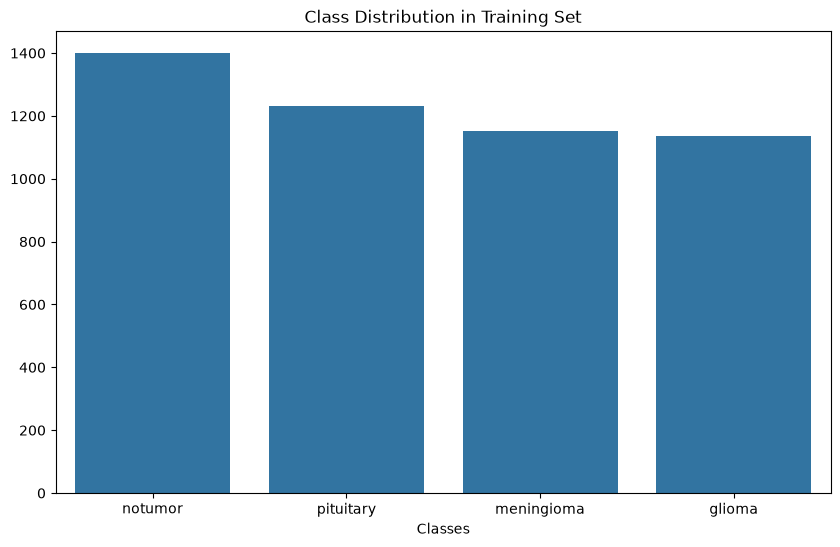

In [19]:
plt.figure(figsize=(10, 6))

sns.barplot(x=counts.index, y=counts.values)
plt.title("Class Distribution in Training Set")
plt.xlabel("Classes")

In [ ]:
def balance_classes (X_train, y_train, target_count=None) :

    if target_count is None : 
        target_count = max(pd.Series(y_train).value_counts())


    classes, counts = np.unique(y_train, return_counts=True) 

    X_balance = list(X_train) 
    Y_balance = list(y_train)

    for cls in classes : 

        indices = np.where(y_train == cls)[0]

        current_count = len(indices)

        num_to_augment = target_count - current_count

        if num_to_augment > 0 : 

            for _ in range(num_to_augment) : 
                
                idx = random.choice(indices) 
                img , label = load_image(X_train[idx], y_train[idx])

                augmented_img, augmented_label = augment_data(img, label)

                X_balance.append(augmented_img) 
                Y_balance.append(augmented_label)


    return np.array(X_balance), np.array(Y_balance)

In [ ]:
feature_extractor = hub.KerasLayer(MODEL_URL, trainable=False)